In [1]:
# EDA Cell 1: imports, load the cleaned data, first look
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ---- find the project root: the first folder (from here upwards) that contains "data" ----
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
CLEAN_DIR = ROOT / "data" / "cleaned_data"
FIG_DIR = ROOT / "EDA" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- chart style and a helper that saves every chart as a picture ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
BLUE = "#0A66C2"


def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


# ---- load the two cleaned files ----
jobs = pd.read_csv(CLEAN_DIR / "jobs_cleaned.csv", parse_dates=["posted_date", "scraped_at"],
                   dtype={"job_id": str})
skills = pd.read_csv(CLEAN_DIR / "job_skills.csv", dtype={"job_id": str})

print("Project root:", ROOT)
print("Jobs table:  ", jobs.shape)
print("Skills table:", skills.shape)
print("\nDistinct companies:", jobs["company"].nunique(), "| cities:", jobs["city"].nunique())
print("\nColumn types:")
print(jobs.dtypes)
jobs[["title", "role_category", "company", "city", "seniority_level", "exp_min_years", "skill_count"]].head()

Project root: C:\Linkedin_Job_Analysis
Jobs table:   (332, 22)
Skills table: (2891, 4)

Distinct companies: 235 | cities: 25

Column types:
job_id                          str
title                           str
role_category                   str
company                         str
location                        str
city                            str
country                         str
is_remote                      bool
posted_date          datetime64[us]
days_since_posted             int64
seniority_level                 str
employment_type                 str
industries                      str
exp_min_years               float64
skill_count                   int64
tech_skill_count              int64
skills                          str
job_url                         str
description                     str
search_keyword                  str
search_location                 str
scraped_at           datetime64[us]
dtype: object


,title,role_category,company,city,seniority_level,exp_min_years,skill_count
0,DATA ANALYST L4,Data Analyst,Wipro,Hyderabad,Not Applicable,5.0,2
1,Principal Data Scientist-GenAI l LLMs l Comput...,Data Scientist,HERE Technologies,Mumbai,Mid-Senior level,10.0,8
2,Associate - Business Analyst-Business Process ...,Business Analyst,EXL,Noida,Entry level,NaN,0
3,Business Analyst,Business Analyst,Flex,Chennai,Entry level,NaN,4
4,Senior Business Systems Analyst,Business Analyst,Franklin Templeton,Hyderabad,Mid-Senior level,6.0,4


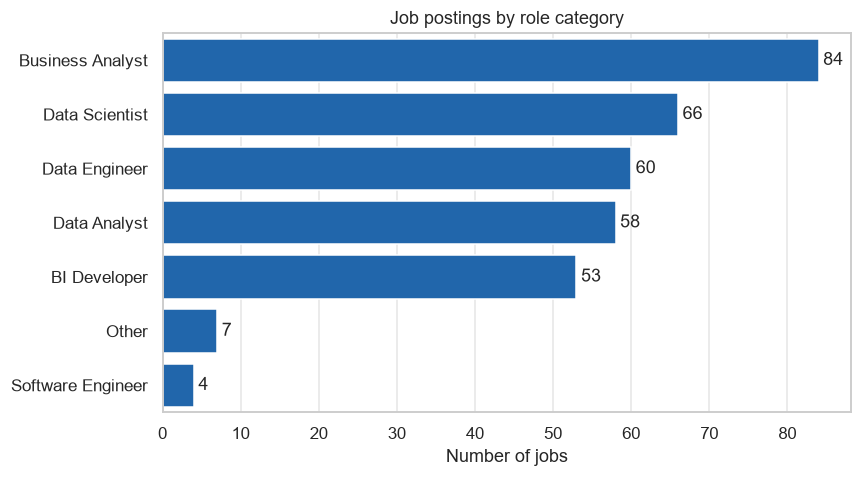

role_category
Business Analyst     84
Data Scientist       66
Data Engineer        60
Data Analyst         58
BI Developer         53
Other                 7
Software Engineer     4
Name: count, dtype: int64


In [2]:
# EDA Cell 2: which roles hire the most?
order = jobs["role_category"].value_counts().index

plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=jobs, y="role_category", order=order, color=BLUE)
ax.bar_label(ax.containers[0], padding=3)
plt.title("Job postings by role category")
plt.xlabel("Number of jobs")
plt.ylabel("")
save("01_roles")

print(jobs["role_category"].value_counts())

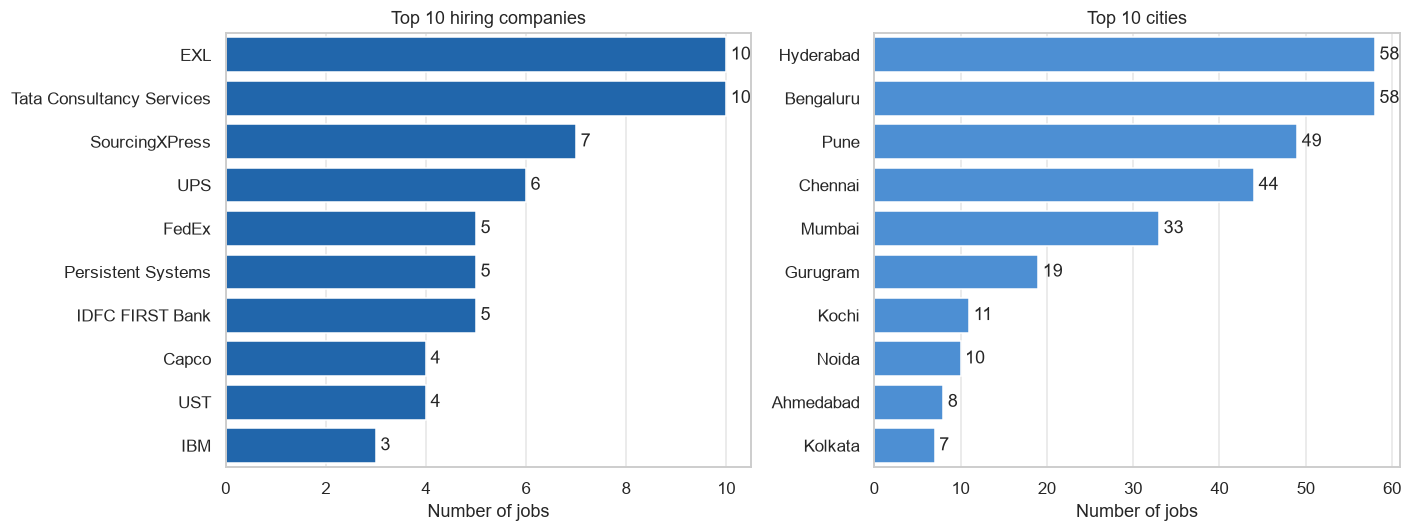

Top companies:
company
EXL                          10
Tata Consultancy Services    10
SourcingXPress                7
UPS                           6
FedEx                         5
Persistent Systems            5
IDFC FIRST Bank               5
Capco                         4
UST                           4
IBM                           3
Name: count, dtype: int64 

Top cities:
city
Hyderabad    58
Bengaluru    58
Pune         49
Chennai      44
Mumbai       33
Gurugram     19
Kochi        11
Noida        10
Ahmedabad     8
Kolkata       7
Name: count, dtype: int64

Jobs with no city listed: 2


In [3]:
# EDA Cell 3: which companies and cities post the most jobs?
top_companies = jobs["company"].value_counts().head(10)
top_cities = jobs["city"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x=top_companies.values, y=top_companies.index, ax=axes[0], color=BLUE)
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Top 10 hiring companies")
axes[0].set_xlabel("Number of jobs")
axes[0].set_ylabel("")

sns.barplot(x=top_cities.values, y=top_cities.index, ax=axes[1], color="#378FE9")
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set_title("Top 10 cities")
axes[1].set_xlabel("Number of jobs")
axes[1].set_ylabel("")
save("02_companies_cities")

print("Top companies:")
print(top_companies, "\n")
print("Top cities:")
print(top_cities)
print("\nJobs with no city listed:", jobs["city"].isna().sum())

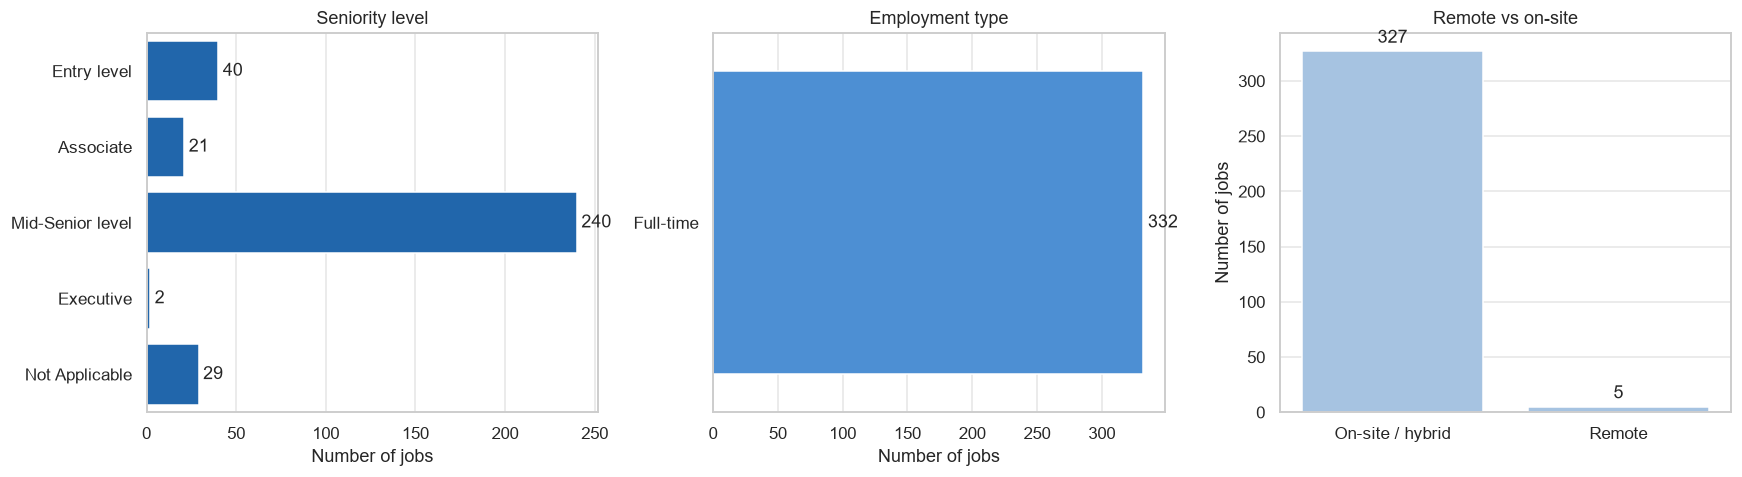

Seniority level:
seniority_level
Entry level          40
Associate            21
Mid-Senior level    240
Executive             2
Not Applicable       29
Name: count, dtype: int64 

Employment type:
employment_type
Full-time    332
Name: count, dtype: int64 

Remote share:  1.5 %

Average minimum experience by seniority level (years):
                  count  mean
seniority_level              
Associate            15   3.9
Entry level          13   2.2
Executive             2   5.0
Mid-Senior level    177   5.0
Not Applicable       22   4.9


In [4]:
# EDA Cell 4: seniority level, job type and remote work
seniority_order = ["Internship", "Entry level", "Associate", "Mid-Senior level", "Director", "Executive",
                   "Not Applicable", "Not specified"]
seniority_order = [s for s in seniority_order if s in set(jobs["seniority_level"])]   # keep only levels that exist
sen_counts = jobs["seniority_level"].value_counts().reindex(seniority_order).dropna()
emp_counts = jobs["employment_type"].value_counts()
remote_counts = jobs["is_remote"].map({True: "Remote", False: "On-site / hybrid"}).value_counts()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.barplot(x=sen_counts.values, y=sen_counts.index, ax=axes[0], color=BLUE)
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Seniority level")
axes[0].set_xlabel("Number of jobs")
axes[0].set_ylabel("")

sns.barplot(x=emp_counts.values, y=emp_counts.index, ax=axes[1], color="#378FE9")
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set_title("Employment type")
axes[1].set_xlabel("Number of jobs")
axes[1].set_ylabel("")

sns.barplot(x=remote_counts.index, y=remote_counts.values, ax=axes[2], color="#9CC3EB")
axes[2].bar_label(axes[2].containers[0], padding=3)
axes[2].set_title("Remote vs on-site")
axes[2].set_xlabel("")
axes[2].set_ylabel("Number of jobs")
save("03_seniority_type_remote")

print("Seniority level:")
print(sen_counts.astype(int), "\n")
print("Employment type:")
print(emp_counts, "\n")
print("Remote share: ", round(jobs["is_remote"].mean() * 100, 1), "%")
print("\nAverage minimum experience by seniority level (years):")
print(jobs.groupby("seniority_level")["exp_min_years"].agg(["count", "mean"]).round(1))

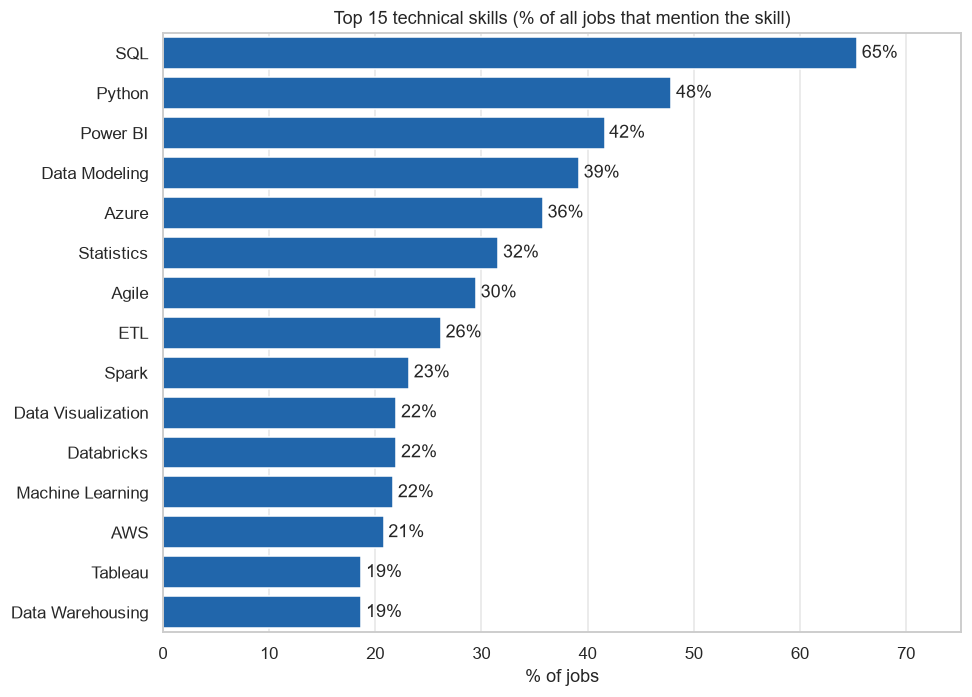

Top 15 technical skills:
             skill  jobs  pct_of_jobs
               SQL   217         65.4
            Python   159         47.9
          Power BI   138         41.6
     Data Modeling   130         39.2
             Azure   119         35.8
        Statistics   105         31.6
             Agile    98         29.5
               ETL    87         26.2
             Spark    77         23.2
Data Visualization    73         22.0
        Databricks    73         22.0
  Machine Learning    72         21.7
               AWS    69         20.8
           Tableau    62         18.7
  Data Warehousing    62         18.7

Soft skills:
                 skill  jobs  pct_of_jobs
Stakeholder Management   228         68.7
         Communication   204         61.4
       Problem Solving   147         44.3


In [5]:
# EDA Cell 5: which skills are most in demand?
n_jobs = len(jobs)
jobs_per_skill = skills.groupby(["skill", "skill_type"])["job_id"].nunique().reset_index(name="jobs")
jobs_per_skill["pct_of_jobs"] = (jobs_per_skill["jobs"] / n_jobs * 100).round(1)

tech = jobs_per_skill[jobs_per_skill["skill_type"] == "Technical"].sort_values("pct_of_jobs", ascending=False)
soft = jobs_per_skill[jobs_per_skill["skill_type"] == "Soft"].sort_values("pct_of_jobs", ascending=False)

top_tech = tech.head(15)
plt.figure(figsize=(9, 6.5))
ax = sns.barplot(data=top_tech, x="pct_of_jobs", y="skill", color=BLUE)
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
plt.title("Top 15 technical skills (% of all jobs that mention the skill)")
plt.xlabel("% of jobs")
plt.ylabel("")
plt.xlim(0, top_tech["pct_of_jobs"].max() * 1.15)
save("04_top_technical_skills")

print("Top 15 technical skills:")
print(top_tech[["skill", "jobs", "pct_of_jobs"]].to_string(index=False))
print("\nSoft skills:")
print(soft[["skill", "jobs", "pct_of_jobs"]].to_string(index=False))

Roles shown: ['Business Analyst', 'Data Scientist', 'Data Engineer', 'Data Analyst', 'BI Developer']
Roles skipped (fewer than 20 jobs): ['Other', 'Software Engineer']


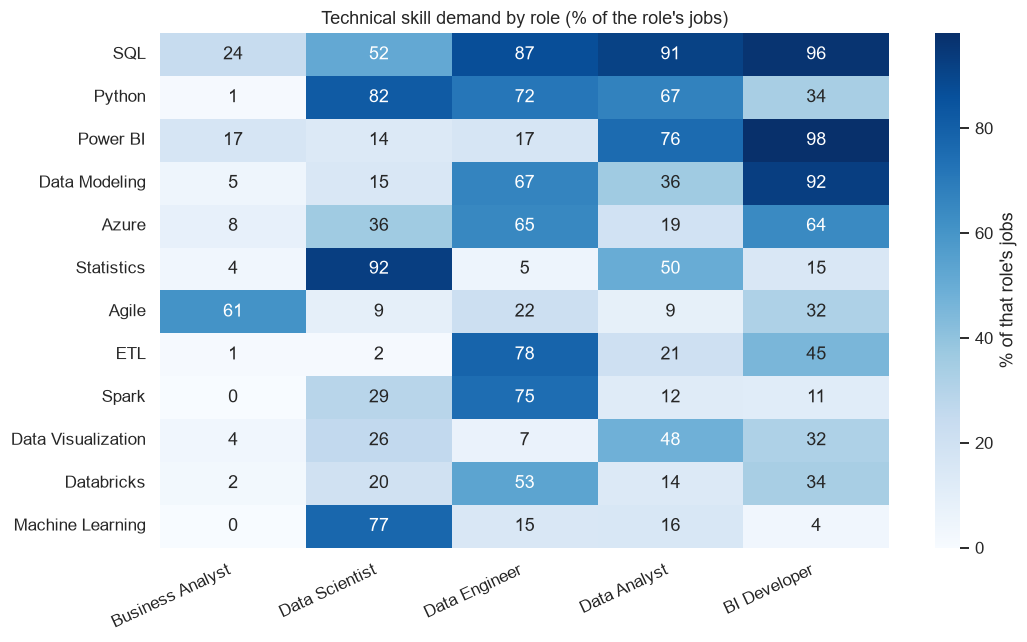


Jobs per role:
role_category
Business Analyst    84
Data Scientist      66
Data Engineer       60
Data Analyst        58
BI Developer        53

Skill demand by role (%):
role_category       Business Analyst  Data Scientist  Data Engineer  Data Analyst  BI Developer
skill                                                                                          
SQL                               24              52             87            91            96
Python                             1              82             72            67            34
Power BI                          17              14             17            76            98
Data Modeling                      5              15             67            36            92
Azure                              8              36             65            19            64
Statistics                         4              92              5            50            15
Agile                             61               9        

In [6]:
# EDA Cell 6: do different roles need different skills?
role_sizes = jobs["role_category"].value_counts()
big_roles = role_sizes[role_sizes >= 20].index            # skip tiny groups: their percentages are too noisy
print("Roles shown:", list(big_roles))
print("Roles skipped (fewer than 20 jobs):", list(role_sizes[role_sizes < 20].index))

merged = skills.merge(jobs[["job_id", "role_category"]], on="job_id")
merged = merged[merged["role_category"].isin(big_roles) & (merged["skill_type"] == "Technical")]

top_skills = skills.loc[skills["skill_type"] == "Technical", "skill"].value_counts().head(12).index

heat = (merged[merged["skill"].isin(top_skills)]
        .groupby(["skill", "role_category"])["job_id"].nunique()
        .unstack(fill_value=0)
        .reindex(index=top_skills, columns=big_roles)
        .fillna(0))
heat = heat.div(role_sizes[big_roles], axis=1).mul(100)   # % of THAT role's jobs

plt.figure(figsize=(10, 6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of that role's jobs"})
plt.title("Technical skill demand by role (% of the role's jobs)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=25, ha="right")
save("05_skills_by_role")

print("\nJobs per role:")
print(role_sizes[big_roles].to_string())
print("\nSkill demand by role (%):")
print(heat.round(0).astype(int).to_string())

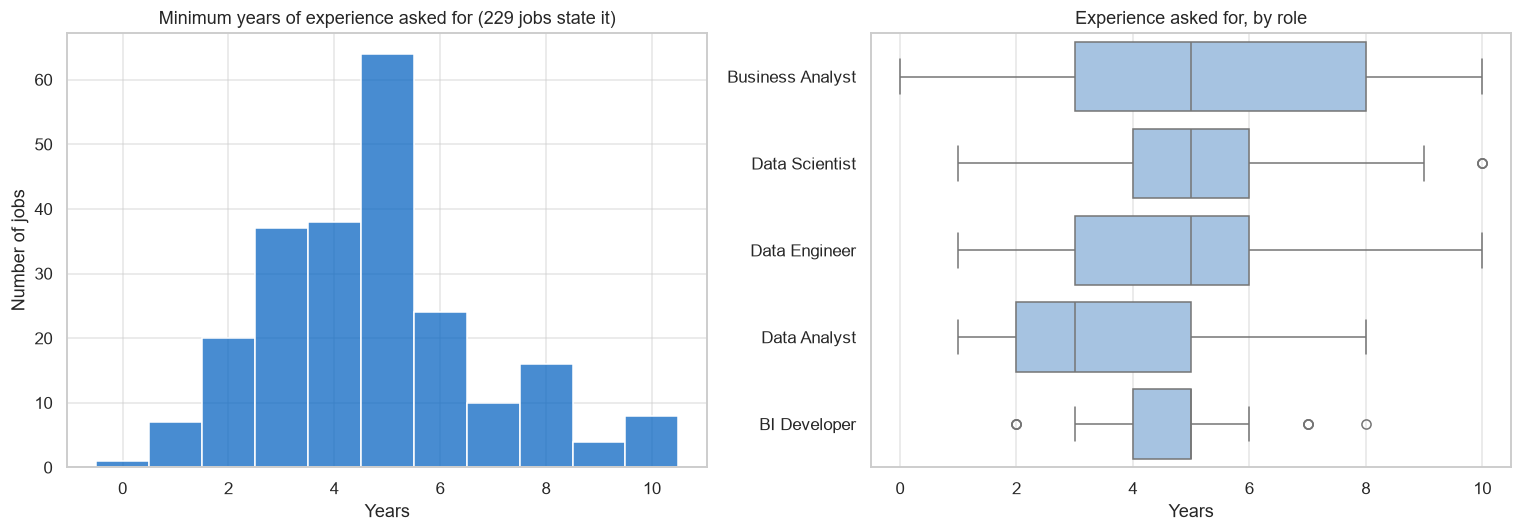

Jobs that state experience: 229 of 332

Median / mean years overall: 5.0 / 4.8

By role (jobs with a value, median, mean):
                   count  median  mean
role_category                         
BI Developer          38     5.0   4.6
Business Analyst      53     5.0   5.3
Data Analyst          40     3.0   3.6
Data Engineer         44     5.0   4.9
Data Scientist        48     5.0   5.1
Other                  5     5.0   5.4
Software Engineer      1     5.0   5.0

Share of jobs stating experience, by role (%):
role_category
BI Developer         72.0
Business Analyst     63.0
Data Analyst         69.0
Data Engineer        73.0
Data Scientist       73.0
Other                71.0
Software Engineer    25.0


In [7]:
# EDA Cell 7: how much experience do employers ask for?
role_sizes = jobs["role_category"].value_counts()
big_roles = list(role_sizes[role_sizes >= 20].index)
exp_jobs = jobs.dropna(subset=["exp_min_years"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(exp_jobs["exp_min_years"], discrete=True, color=BLUE, ax=axes[0])
axes[0].set_title(f"Minimum years of experience asked for ({len(exp_jobs)} jobs state it)")
axes[0].set_xlabel("Years")
axes[0].set_ylabel("Number of jobs")

sns.boxplot(data=exp_jobs[exp_jobs["role_category"].isin(big_roles)], x="exp_min_years",
            y="role_category", order=big_roles, color="#9CC3EB", ax=axes[1])
axes[1].set_title("Experience asked for, by role")
axes[1].set_xlabel("Years")
axes[1].set_ylabel("")
save("06_experience")

print("Jobs that state experience:", len(exp_jobs), "of", len(jobs))
print("\nMedian / mean years overall:", exp_jobs["exp_min_years"].median(), "/", round(exp_jobs["exp_min_years"].mean(), 1))
print("\nBy role (jobs with a value, median, mean):")
print(exp_jobs.groupby("role_category")["exp_min_years"].agg(["count", "median", "mean"]).round(1).to_string())
print("\nShare of jobs stating experience, by role (%):")
print((jobs.groupby("role_category")["exp_min_years"].apply(lambda s: s.notna().mean() * 100)).round(0).to_string())

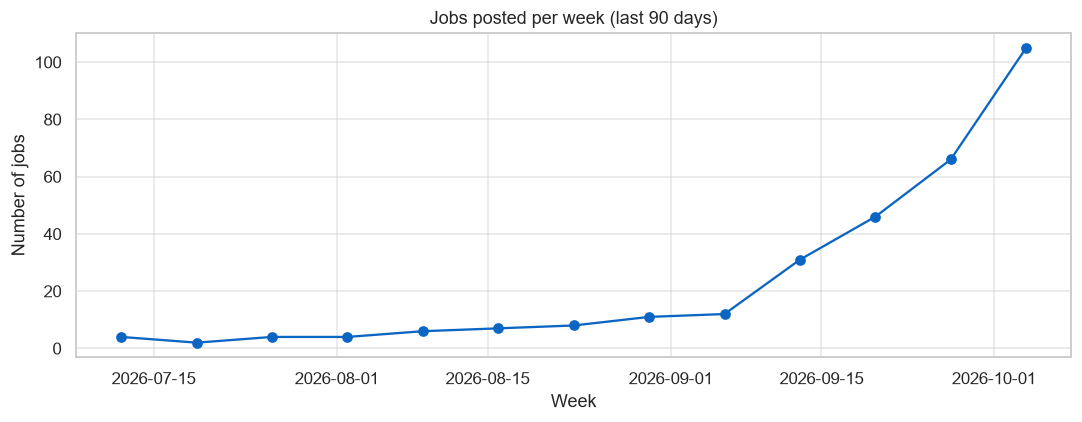

Jobs posted in the last 90 days: 306 of 332
Older than 90 days (left out of the chart): 26

Jobs posted per week:
posted_date
2026-07-12      4
2026-07-19      2
2026-07-26      4
2026-08-02      4
2026-08-09      6
2026-08-16      7
2026-08-23      8
2026-08-30     11
2026-09-06     12
2026-09-13     31
2026-09-20     46
2026-09-27     66
2026-10-04    105
Freq: W-SUN


In [8]:
# EDA Cell 8: when were the jobs posted? (last 90 days only)
recent = jobs[jobs["days_since_posted"] <= 90]
weekly = recent.set_index("posted_date").resample("W").size()

plt.figure(figsize=(10, 4))
plt.plot(weekly.index, weekly.values, marker="o", color=BLUE)
plt.title("Jobs posted per week (last 90 days)")
plt.xlabel("Week")
plt.ylabel("Number of jobs")
save("07_weekly_postings")

print("Jobs posted in the last 90 days:", len(recent), "of", len(jobs))
print("Older than 90 days (left out of the chart):", len(jobs) - len(recent))
print("\nJobs posted per week:")
print(weekly.to_string())

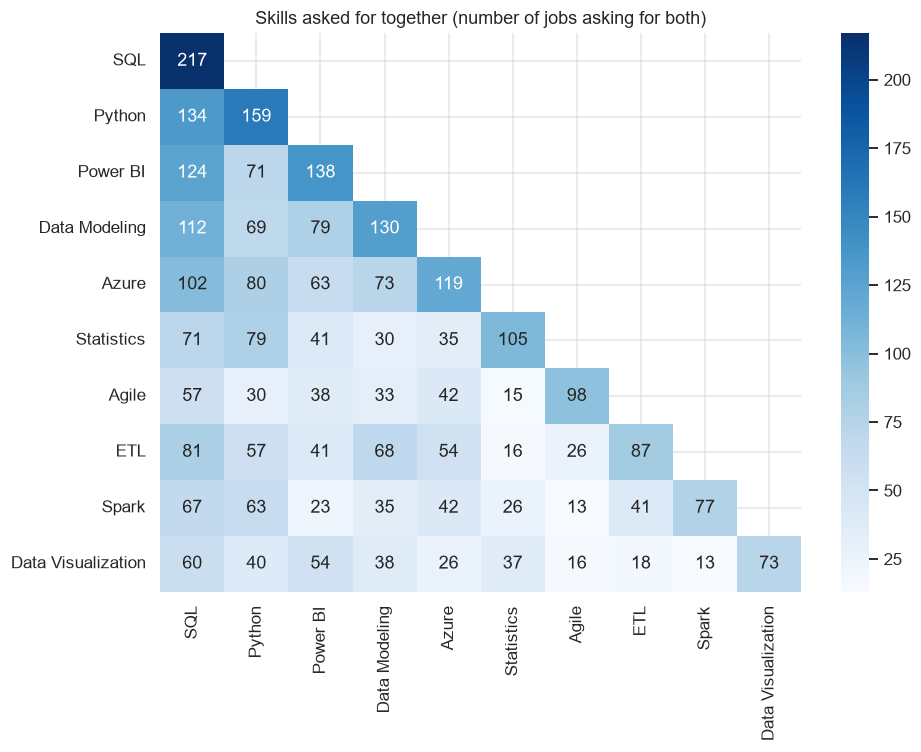

Top 8 skill pairs:
      skill_a  skill_b  jobs
       Python      SQL   134
     Power BI      SQL   124
Data Modeling      SQL   112
        Azure      SQL   102
          ETL      SQL    81
        Azure   Python    80
Data Modeling Power BI    79
   Statistics   Python    79


In [9]:
# EDA Cell 9: which technical skills are asked for together?
top10 = skills.loc[skills["skill_type"] == "Technical", "skill"].value_counts().head(10).index
presence = (skills[skills["skill"].isin(top10)]
            .assign(v=1)
            .pivot_table(index="job_id", columns="skill", values="v", fill_value=0)
            .astype(int))
cooc = presence.T.dot(presence).reindex(index=top10, columns=top10)

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(cooc, dtype=bool), k=1)
sns.heatmap(cooc, mask=mask, annot=True, fmt="d", cmap="Blues")
plt.title("Skills asked for together (number of jobs asking for both)")
plt.xlabel("")
plt.ylabel("")
save("08_skill_pairs")

names = list(cooc.index)
pairs = pd.DataFrame([(a, b, int(cooc.loc[a, b])) for i, a in enumerate(names) for b in names[:i]],
                     columns=["skill_a", "skill_b", "jobs"]).sort_values("jobs", ascending=False)
print("Top 8 skill pairs:")
print(pairs.head(8).to_string(index=False))

 # Key findings

**Dataset:** 332 LinkedIn job postings from India, collected through five searches (Data Analyst, Data Scientist,
Data Engineer, Business Analyst, Power BI Developer), covering 235 companies and 25 cities.
Postings range from April 2025 to October 2026; 26 are older than 90 days.

1. **SQL is the most requested technical skill (65% of jobs)**, followed by Python (48%), Power BI (42%),
   Data Modeling (39%) and Azure (36%). Among soft skills, stakeholder management (69%) and communication (61%)
   are mentioned most.
2. **Skills come in bundles.** 84% of the jobs that ask for Python also ask for SQL (134 of 159), and 90% of the
   Power BI jobs also ask for SQL (124 of 138).
3. **Each role has a clear skill profile.** Data Scientist: Statistics 92%, Python 82%, Machine Learning 77%.
   Data Engineer: SQL 87%, ETL 78%, Spark 75%. BI Developer: Power BI 98%, SQL 96%, Data Modeling 92%.
   Business Analyst postings mention few tools (SQL 24%, Agile 61%), so they look more like process roles.
4. **Experience:** among the 69% of jobs that state a requirement, the median is 5 years. Data Analyst roles are the
   most junior, with a median of 3 years.
5. **Seniority:** 72% of jobs are Mid-Senior level, 12% Entry level.
6. **Location:** Bengaluru and Hyderabad lead with 58 jobs each, then Pune (49), Chennai (44) and Mumbai (33).

## Limits of this analysis
- The jobs come from five searches, so the number of jobs per role reflects how I scraped, not market demand.
- A skill counts when its name appears in the description, whether required or "nice to have".
- Remote work is a lower bound: only 5 jobs (1.5%) say so in the title or location.
- All 332 jobs are listed as Full-time, so job type says nothing about the market.
- 31% of jobs do not state an experience requirement.